# P1. Que tempo fixo?

## 3. Datos

Se trabaja con datos meteorológicos diarios de la estación A Coruña / Alvedro (indicativo 08002), correspondientes al período 2021–2025. La fuente original es Meteostat; el fichero facilitado para la práctica ha sido modificado con fines didácticos para incluir problemas de calidad.

Fuente de descarga: https://github.com/bigdatawirtz/datasets/blob/main/datasets/meteo_alvedro_2021_2025.csv

## 4.2. Obtención y almacenamiento de los datos

Se descarga el archivo mediante Python y se guarda sin modificar en `datos/raw/`. De esta forma, el notebook puede obtener los datos aunque esa carpeta esté vacía al empezar.


In [2]:
import requests
from pathlib import Path

URL = "https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv"

destino = Path("../datos/raw/meteo_alvedro_2021_2025.csv")

# Crear las carpetas si todavía no existen
destino.parent.mkdir(parents=True, exist_ok=True)

# Descargar el archivo
respuesta = requests.get(URL, timeout=30)
respuesta.raise_for_status()

# Guardar los bytes originales sin modificarlos
destino.write_bytes(respuesta.content)

print("Archivo descargado correctamente.")
print("Tamaño:", destino.stat().st_size, "bytes")

Archivo descargado correctamente.
Tamaño: 81825 bytes


## 4.3. Procesamiento y limpieza de los datos

Se inspecciona primero el fichero original y después se comprueban formatos, tipos, ausencias y posibles errores. Las correcciones se aplicarán más adelante, tras documentar los problemas encontrados.

### Localización del archivo original

In [3]:
from pathlib import Path

ruta = Path("../datos/raw/meteo_alvedro_2021_2025.csv")

print("¿Existe el archivo?", ruta.exists())

¿Existe el archivo? True


### Inspección de bytes y codificación

In [4]:
with open(ruta, "rb") as archivo:
    primeros_bytes = archivo.read(200)

print(primeros_bytes)

b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\nEstaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo: 08002\nLatitude: 43,3000 \xb7 Lonxitude: -8,3833 \xb7 Altitude: 97 m\nPer\xedodo: 01/01/2021 - 31/12/2025\nFon'


### Exploración de las primeras y últimas líneas

In [5]:
with open(ruta, "r", encoding="latin-1") as archivo:
    lineas = archivo.readlines()

print("Número total de líneas:", len(lineas))

print("\nPRIMERAS 10 LÍNEAS:")
for linea in lineas[:10]:
    print(repr(linea))

print("\nÚLTIMAS 5 LÍNEAS:")
for linea in lineas[-5:]:
    print(repr(linea))

Número total de líneas: 1819

PRIMERAS 10 LÍNEAS:
'Servizo de exportación de datos meteorolóxicos\n'
'Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002\n'
'Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m\n'
'Período: 01/01/2021 - 31/12/2025\n'
'Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.\n'
'\n'
'Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)\n'
'2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7\n'
'2021-01-02;5,5;3,1;9,7;91;9,8;6,4;1.019,8\n'
'2021-01-03;5,6;3,0;8,4;92;12,4;8,5;1.018,9\n'

ÚLTIMAS 5 LÍNEAS:
'2025-06-10;20,8;15,6;27,6;80;Ip;6,2;1.015,7\n'
'2021-04-16;10,0;3,6;17,2;56;0,0;11,7;1.020,1\n'
'2022-05-21;19,9;10,9;24,7;81;2,9;5,8;1.015,6\n'
'2025-10-12;17,6;9,9;24,9;74;0,0;5,8;1.018,8\n'
'17/08/2023;20,1;14,2;26,7;77;0,5;9,3;1.014,7\n'


### Observaciones iniciales

El archivo contiene 1819 líneas, incluyendo metadatos iniciales sobre la estación meteorológica.

La lectura preliminar con codificación Latin-1 permite visualizar correctamente los caracteres especiales.

Los campos parecen estar separados por punto y coma (`;`) y los valores numéricos utilizan coma decimal (`,`).

Las últimas líneas no están ordenadas cronológicamente, por lo que será necesario revisar las fechas durante la limpieza.

In [6]:
# Separar los registros de los metadatos
registros = lineas[7:]

# Mostrar las columnas del CSV
columnas = lineas[6].strip().split(";")

print("Columnas del archivo:")
for columna in columnas:
    print("-", columna)

# Buscar posibles valores ausentes
print("\nEjemplos de registros con valores sospechosos:")

for registro in registros:
    if "NA" in registro or "Ip" in registro or ";;" in registro:
        print(registro.strip())
        break

Columnas del archivo:
- Data
- Temp. media (ºC)
- Temp. mínima (ºC)
- Temp. máxima (ºC)
- Humidade relativa (%)
- Precipitación (mm)
- Vento medio (km/h)
- Presión (hPa)

Ejemplos de registros con valores sospechosos:
2021-01-15;8,2;1,9;12,7;88;Ip;5,6;1.031,4


### Observaciones sobre el formato

El archivo contiene 8 columnas con información meteorológica diaria.

Se ha identificado que:
- Las columnas están separadas por punto y coma (`;`).
- Los valores numéricos utilizan coma decimal y, en algunos casos, punto como separador de miles.
- Las primeras 6 líneas contienen metadatos, y la séptima corresponde a las cabeceras.
- Aparece el código `Ip` en la precipitación, cuyo significado y tratamiento deben verificarse.
- Las últimas filas no están ordenadas cronológicamente.
### Lectura inicial con pandas

In [7]:
import pandas as pd

df = pd.read_csv(
    ruta,
    encoding="latin-1",
    sep=";",
    decimal=",",
    thousands=".",
    skiprows=6
)

df.head()

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,1014.6


### Comprobación de tipos de datos

Se comprueban los tipos asignados por pandas a cada columna y la cantidad de valores no nulos, con el objetivo de identificar posibles problemas de interpretación.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Data                   1812 non-null   str    
 1   Temp. media (ºC)       1803 non-null   float64
 2   Temp. mínima (ºC)      1806 non-null   float64
 3   Temp. máxima (ºC)      1803 non-null   float64
 4   Humidade relativa (%)  1812 non-null   int64  
 5   Precipitación (mm)     1804 non-null   str    
 6   Vento medio (km/h)     1812 non-null   float64
 7   Presión (hPa)          1811 non-null   float64
dtypes: float64(5), int64(1), str(2)
memory usage: 113.4 KB


### Observaciones

El DataFrame contiene 1812 registros y 8 columnas.

Se detectan dos columnas con tipos que requieren revisión:
- `Data`: se ha interpretado como texto en lugar de fecha.
- `Precipitación (mm)`: se ha interpretado como texto debido a la presencia de valores no numéricos.

También se observan valores ausentes en varias columnas de temperatura, precipitación y presión.

Será necesario investigar estos problemas antes de realizar el análisis.

### Análisis de valores especiales en precipitación

Se analizan los valores de la columna de precipitación para identificar códigos no numéricos que impiden su correcta interpretación.

Antes de realizar cualquier conversión, se comprueba qué valores aparecen y cuántas veces se repiten.

In [9]:
# Seleccionar la columna de precipitación
precipitacion = df["Precipitación (mm)"]

# Mostrar los valores más frecuentes
print("Valores más frecuentes:")
print(precipitacion.value_counts().head(20))

# Comprobar valores ausentes
print("\nValores nulos:", precipitacion.isna().sum())

Valores más frecuentes:
Precipitación (mm)
0,0    809
Ip     121
0,2     49
0,3     34
0,4     29
0,5     28
0,7     23
0,9     21
0,8     19
1,2     16
1,0     15
2,1     14
0,6     14
1,9     14
1,6     13
1,1     12
3,6     12
1,4     12
2,9     12
2,6     12
Name: count, dtype: int64

Valores nulos: 8


### Identificación de valores no numéricos

Se identifican los valores de precipitación que no pueden convertirse a números, con el objetivo de localizar posibles códigos especiales o errores de formato.

In [10]:
# Sustituir la coma decimal por un punto
precip_texto = precipitacion.str.replace(",", ".", regex=False)

# Intentar convertir los valores a números
precip_numerica = pd.to_numeric(precip_texto, errors="coerce")

# Detectar valores que no se han podido convertir
no_numericos = precipitacion[
    precip_numerica.isna() & precipitacion.notna()
]

print("Valores no numéricos encontrados:")
print(no_numericos.value_counts())

Valores no numéricos encontrados:
Precipitación (mm)
Ip    121
Name: count, dtype: int64


### Análisis de valores ausentes

Se identifican los registros que contienen valores nulos y las variables afectadas.

El objetivo es determinar si los valores ausentes corresponden a errores puntuales o a registros incompletos antes de decidir cómo tratarlos.

In [11]:
# Contar los valores nulos de cada columna
print("Valores nulos por columna:")
print(df.isna().sum())

# Mostrar las filas que contienen al menos un valor nulo
filas_nulas = df[df.isna().any(axis=1)]

print("\nRegistros con valores ausentes:")
display(filas_nulas)

Valores nulos por columna:
Data                     0
Temp. media (ºC)         9
Temp. mínima (ºC)        6
Temp. máxima (ºC)        9
Humidade relativa (%)    0
Precipitación (mm)       8
Vento medio (km/h)       0
Presión (hPa)            1
dtype: int64

Registros con valores ausentes:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
164,2021-06-16,18.0,15.7,19.5,90,NaN,7.4,1011.6
175,2021-06-27,NaN,10.2,18.4,79,Ip,13.8,1017.8
211,2021-08-02,NaN,12.8,21.2,79,"0,0",11.2,1018.8
295,2021-10-25,14.1,NaN,18.5,87,Ip,8.7,1023.3
313,2021-11-12,10.3,3.3,16.4,90,NaN,7.5,1021.5
338,2021-12-08,9.0,4.5,NaN,79,"5,9",22.0,1016.7
350,2021-12-20,13.6,NaN,16.5,62,"1,1",15.8,1015.9
376,2022-01-15,6.7,NaN,14.0,72,"0,0",12.5,1026.9
408,2022-02-16,14.2,11.8,NaN,80,"0,0",13.9,1027.4
506,2022-05-25,NaN,8.7,18.4,81,"0,8",10.1,1025.4


### Validación e interpretación de fechas

Se comprueba que todas las fechas del archivo sean válidas y se identifican posibles diferencias en su formato.

Se utiliza `pd.to_datetime()` para interpretar las fechas, admitiendo tanto el formato `AAAA-MM-DD` como `DD/MM/AAAA`.

Los valores que no puedan interpretarse correctamente se convertirán en `NaT`, permitiendo detectar posibles errores.

In [12]:
# Identificar las fechas que utilizan barras
formato_barras = df["Data"].str.contains("/", regex=False)

# Crear una serie para almacenar las fechas convertidas
fechas_convertidas = pd.Series(
    pd.NaT,
    index=df.index,
    dtype="datetime64[ns]"
)

# Convertir fechas con formato AAAA-MM-DD
fechas_convertidas.loc[~formato_barras] = pd.to_datetime(
    df.loc[~formato_barras, "Data"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Convertir fechas con formato DD/MM/AAAA
fechas_convertidas.loc[formato_barras] = pd.to_datetime(
    df.loc[formato_barras, "Data"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Fechas no válidas:", fechas_convertidas.isna().sum())

print("\nEjemplos de conversión:")
display(pd.DataFrame({
    "Original": df["Data"],
    "Convertida": fechas_convertidas
}).loc[[179, 906, 907, 1811]])

Fechas no válidas: 0

Ejemplos de conversión:


,Original,Convertida
179,2021-07-01,2021-07-01
906,01/07/2023,2023-07-01
907,02/07/2023,2023-07-02
1811,17/08/2023,2023-08-17


**Resultados:**

- Las 1812 fechas se han convertido correctamente, sin producir valores `NaT`.
- Se han detectado fechas con formatos diferentes, principalmente `AAAA-MM-DD` y `DD/MM/AAAA`.
- Se ha observado que algunas fechas no siguen el orden cronológico esperado.

**Decisión:** se utilizarán fechas de tipo `datetime` en el conjunto de datos limpio para unificar el formato y facilitar los análisis temporales.

### Detección de fechas duplicadas y días ausentes

Se comprueba si existen varios registros correspondientes a una misma fecha y si faltan días dentro del período comprendido entre el 01/01/2021 y el 31/12/2025.

Estas comprobaciones permiten detectar problemas de integridad temporal antes de limpiar los datos.

In [13]:
# Comprobar fechas duplicadas
duplicados = fechas_convertidas.duplicated(keep=False)

print("Registros con fechas duplicadas:", duplicados.sum())

display(df.loc[duplicados].assign(
    fecha_normalizada=fechas_convertidas[duplicados]
).sort_values("fecha_normalizada"))

# Generar todas las fechas que deberían existir
fechas_esperadas = pd.date_range(
    start="2021-01-01",
    end="2025-12-31",
    freq="D"
)

# Buscar fechas que faltan
fechas_faltantes = fechas_esperadas.difference(
    pd.DatetimeIndex(fechas_convertidas)
)

print("\nNúmero de días ausentes:", len(fechas_faltantes))
print("\nFechas que faltan:")
print(fechas_faltantes)

Registros con fechas duplicadas: 26


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa),fecha_normalizada
104,2021-04-16,11.1,2.5,18.2,56,"0,0",11.7,1020.1,2021-04-16
1808,2021-04-16,10.0,3.6,17.2,56,"0,0",11.7,1020.1,2021-04-16
179,2021-07-01,17.9,13.6,22.8,78,"0,0",7.7,1018.6,2021-07-01
1806,2021-07-01,19.3,14.2,21.5,78,"0,0",7.7,1018.6,2021-07-01
502,2022-05-21,18.8,11.9,23.3,81,"2,9",5.8,1015.6,2022-05-21
1809,2022-05-21,19.9,10.9,24.7,81,"2,9",5.8,1015.6,2022-05-21
536,2022-06-24,16.4,13.2,19.0,83,"7,8",16.1,1015.2,2022-06-24
1802,2022-06-24,16.4,13.2,19.0,83,"7,8",16.1,1015.2,2022-06-24
1811,17/08/2023,20.1,14.2,26.7,77,"0,5",9.3,1014.7,2023-08-17
932,17/08/2023,20.1,14.2,26.7,77,"0,5",9.3,1014.7,2023-08-17



Número de días ausentes: 27

Fechas que faltan:
DatetimeIndex(['2021-02-17', '2021-05-25', '2021-11-19', '2022-10-21',
               '2023-04-23', '2023-07-03', '2023-07-04', '2023-07-05',
               '2023-07-06', '2023-07-07', '2023-07-08', '2023-07-09',
               '2023-07-10', '2023-07-11', '2023-07-12', '2023-07-13',
               '2023-07-14', '2023-07-15', '2023-07-16', '2023-07-17',
               '2023-07-18', '2023-07-19', '2023-07-20', '2023-07-21',
               '2023-07-22', '2023-07-23', '2024-03-20'],
              dtype='datetime64[us]', freq=None)


**Resultados:**

- Se identifican 26 registros asociados a 13 fechas duplicadas.
- Algunos registros son idénticos, mientras que otros presentan mediciones contradictorias.
- Se detectan 27 días sin registros meteorológicos.
- Entre el 03/07/2023 y el 23/07/2023 existe un período continuo sin datos.

**Decisión pendiente:** los duplicados idénticos podrán eliminarse conservando una copia. Para los duplicados contradictorios será necesario establecer un criterio de selección.

Los días ausentes se documentarán sin inventar mediciones meteorológicas.

### Clasificación de registros duplicados

Se comparan los registros que comparten fecha para distinguir duplicados exactos de registros con mediciones diferentes.

Esta distinción permite decidir cómo tratar cada caso sin eliminar información de forma arbitraria.

In [14]:
# Crear una copia temporal con las fechas normalizadas
df_revision = df.copy()
df_revision["Data"] = fechas_convertidas

# Obtener las filas con fechas repetidas
repetidos = df_revision[
    df_revision.duplicated(subset=["Data"], keep=False)
]

# Contar las versiones distintas de cada fecha
versiones = repetidos.groupby("Data").apply(
    lambda grupo: len(grupo.drop_duplicates()),
    include_groups=False
)

print("Fechas con registros idénticos:")
print(versiones[versiones == 1])

print("\nFechas con registros contradictorios:")
print(versiones[versiones > 1])

Fechas con registros idénticos:
Data
2022-06-24    1
2023-08-17    1
2024-02-15    1
2024-11-17    1
2025-06-10    1
2025-09-21    1
2025-10-12    1
2025-10-19    1
dtype: int64

Fechas con registros contradictorios:
Data
2021-04-16    2
2021-07-01    2
2022-05-21    2
2024-05-18    2
2025-11-22    2
dtype: int64


**Resultados:**

Se han identificado 13 fechas duplicadas:

- 8 fechas presentan registros completamente idénticos.
- 5 fechas presentan registros con diferencias en las temperaturas.

**Tratamiento propuesto:**

- Para los duplicados idénticos, se conservará una única fila.
- Para los duplicados contradictorios, se conservará provisionalmente el primer registro, dejando constancia de que no es posible determinar cuál es correcto sin consultar una fuente externa.

La eliminación de duplicados se realizará durante la fase de limpieza.

### Exploración de valores extremos

Se calculan los valores mínimos y máximos de las variables numéricas para detectar posibles errores, valores imposibles o mediciones meteorológicas anómalas.

Los valores extremos se investigarán antes de decidir si deben corregirse o eliminarse.

In [15]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Temp. media (ºC),1803.0,-2.066778,408.259393,-9999.0,11.35,14.70,18.0,31.3
Temp. mínima (ºC),1806.0,-22.937265,576.147487,-9999.0,7.10,10.90,14.0,21.1
Temp. máxima (ºC),1803.0,2.546312,408.453931,-9999.0,15.40,18.90,22.8,39.2
Humidade relativa (%),1812.0,80.209161,8.089905,36.0,76.00,81.00,86.0,100.0
Vento medio (km/h),1812.0,11.928091,5.226242,3.2,8.10,10.35,14.9,38.5
Presión (hPa),1811.0,1018.171894,7.342351,987.9,1014.45,1018.50,1022.5,1037.9


### Identificación de valores centinela

Durante la exploración estadística se ha detectado el valor `-9999` en las columnas de temperatura.

Este valor no corresponde a una medición meteorológica real y probablemente se utiliza para representar datos ausentes.

Se localizan los registros afectados antes de decidir cómo tratarlos.

In [16]:
# Seleccionar las columnas de temperatura
columnas_temp = [
    "Temp. media (ºC)",
    "Temp. mínima (ºC)",
    "Temp. máxima (ºC)"
]

# Contar cuántos valores -9999 aparecen en cada columna
print("Valores -9999 por columna:")
print((df[columnas_temp] == -9999).sum())

# Identificar todas las filas afectadas
mascara = (df[columnas_temp] == -9999).any(axis=1)

print("\nRegistros afectados:")
display(df.loc[mascara])

Valores -9999 por columna:
Temp. media (ºC)     3
Temp. mínima (ºC)    6
Temp. máxima (ºC)    3
dtype: int64

Registros afectados:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
277,2021-10-07,16.6,11.7,-9999.0,78,Ip,7.5,1022.1
297,2021-10-27,-9999.0,7.2,21.8,84,"0,0",7.9,1021.1
533,2022-06-21,-9999.0,11.7,19.1,84,"3,5",6.8,1012.9
539,2022-06-27,14.4,-9999.0,18.8,75,"0,0",10.4,1022.8
585,2022-08-12,19.1,-9999.0,25.0,84,"0,0",7.7,1015.8
1037,30/11/2023,9.8,6.7,-9999.0,81,"3,7",12.6,1002.2
1122,2024-02-23,8.7,5.7,-9999.0,76,"8,8",25.9,1011.3
1166,2024-04-08,-9999.0,8.7,13.7,75,"6,3",19.8,1012.1
1189,2024-05-01,8.6,-9999.0,14.3,75,"3,1",15.4,1012.6
1573,2025-05-20,16.9,-9999.0,20.5,78,"0,3",9.5,1023.4


**Resultados:**

Se han identificado 12 valores `-9999` distribuidos entre las columnas de temperatura:
- Temperatura media: 3 valores.
- Temperatura mínima: 6 valores.
- Temperatura máxima: 3 valores.

**Decisión:** se sustituirán por `NaN` durante la limpieza, ya que representan datos ausentes y no temperaturas reales.

Se conservarán los demás valores válidos de los registros afectados.

### Visualización de los datos originales

Se representa la evolución de la temperatura media diaria antes de realizar la limpieza.

El objetivo es identificar visualmente valores anómalos y comprobar cómo afectan a la interpretación de los datos.

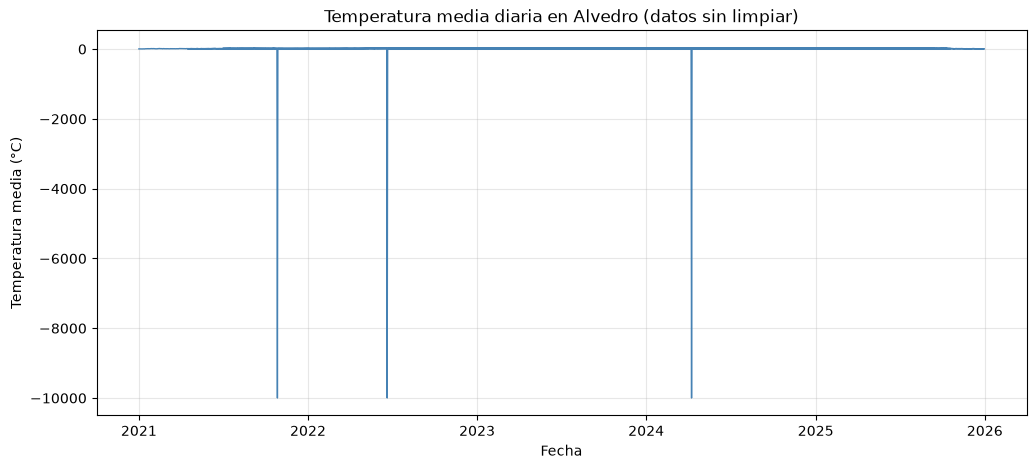

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    fechas_convertidas,
    df["Temp. media (ºC)"],
    color="steelblue",
    linewidth=1
)

plt.title("Temperatura media diaria en Alvedro (datos sin limpiar)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura media (°C)")
plt.grid(True, alpha=0.3)

plt.show()

**Interpretación:**

La gráfica muestra tres caídas anómalas hasta -9999 °C, correspondientes a valores centinela presentes en la temperatura media.

Estos valores distorsionan la escala del eje vertical, impidiendo apreciar correctamente la evolución real de las temperaturas.

Esto demuestra la importancia de detectar y tratar valores erróneos antes de realizar análisis estadísticos y visualizaciones.

### Detección de inconsistencias entre temperaturas

Se comprueba que las temperaturas mínimas, medias y máximas cumplan la relación:

**Temperatura mínima ≤ Temperatura media ≤ Temperatura máxima**

Se identifican los registros que incumplen esta condición para investigar posibles errores de medición o introducción de datos.

In [18]:
# Seleccionar las columnas de temperatura
tmin = df["Temp. mínima (ºC)"]
tmed = df["Temp. media (ºC)"]
tmax = df["Temp. máxima (ºC)"]

# Comprobar las inconsistencias
inconsistencias = (
    (tmin > tmed) |
    (tmed > tmax) |
    (tmin > tmax)
)

# Excluir registros con -9999, ya identificados anteriormente
valores_validos = (
    (df[columnas_temp] != -9999).all(axis=1)
)

inconsistencias = inconsistencias & valores_validos

print("Registros con temperaturas inconsistentes:", inconsistencias.sum())

display(df.loc[inconsistencias])

Registros con temperaturas inconsistentes: 1


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
1477,2025-02-13,31.3,12.3,15.2,91,"2,3",16.6,1018.6


**Resultados:**

Se ha detectado un registro con temperaturas inconsistentes, correspondiente al 13/02/2025.

La temperatura media registrada (31,3 °C) supera la temperatura máxima del día (15,2 °C), incumpliendo la relación:

Temperatura mínima ≤ Temperatura media ≤ Temperatura máxima.

**Decisión:** durante la limpieza se marcará la temperatura media como `NaN`, al no poder determinarse su valor correcto. Se conservarán las demás mediciones, dejando constancia de esta limitación.

### Detección de temperaturas extremas

Se analizan los valores máximos y mínimos de temperatura, excluyendo los códigos centinela `-9999`.

El objetivo es identificar mediciones inusuales que puedan corresponder a fenómenos meteorológicos extremos o errores en los datos.

In [19]:
# Crear una copia temporal para investigar
df_extremos = df.copy()

# Excluir los valores centinela
df_extremos[columnas_temp] = df_extremos[columnas_temp].replace(-9999, float("nan"))

# Mostrar los 10 días con mayor temperatura máxima
print("Temperaturas máximas más altas:")
display(
    df_extremos.nlargest(10, "Temp. máxima (ºC)")[
        ["Data", "Temp. media (ºC)", "Temp. mínima (ºC)", "Temp. máxima (ºC)"]
    ]
)

# Mostrar los 10 días con menor temperatura mínima
print("\nTemperaturas mínimas más bajas:")
display(
    df_extremos.nsmallest(10, "Temp. mínima (ºC)")[
        ["Data", "Temp. media (ºC)", "Temp. mínima (ºC)", "Temp. máxima (ºC)"]
    ]
)

Temperaturas máximas más altas:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
1147,2024-03-19,10.6,7.2,39.2
938,23/08/2023,26.6,21.1,37.2
1513,2025-03-21,11.5,9.3,36.2
246,2021-09-06,23.7,18.0,35.9
556,2022-07-14,26.7,19.1,34.4
551,2022-07-09,25.2,14.9,34.3
923,08/08/2023,22.8,13.3,34.3
555,2022-07-13,25.1,17.5,34.2
983,07/10/2023,23.4,15.4,33.9
1602,2025-06-18,23.3,17.3,33.6



Temperaturas mínimas más bajas:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
7,2021-01-08,2.5,-3.2,8.8
250,2021-09-10,19.3,-2.7,22.9
5,2021-01-06,2.1,-2.5,8.6
6,2021-01-07,2.3,-2.4,8.7
11,2021-01-12,3.1,-2.3,10.6
756,2023-01-31,4.9,-2.3,12.2
786,2023-03-02,4.9,-2.3,12.0
1080,2024-01-12,4.2,-2.0,11.1
384,2022-01-23,5.1,-1.8,14.6
1088,2024-01-20,5.7,-1.8,12.6


**Resultados:**

Se han identificado tres registros especialmente sospechosos:

- 19/03/2024: temperatura máxima de 39,2 °C, con una media de 10,6 °C.
- 21/03/2025: temperatura máxima de 36,2 °C, con una media de 11,5 °C.
- 10/09/2021: temperatura mínima de -2,7 °C, con una media de 19,3 °C.

Aunque estos registros cumplen la relación entre temperaturas mínima, media y máxima, presentan valores inusuales para la época del año y diferencias térmicas considerables.

**Decisión pendiente:** comparar estas mediciones con los días próximos antes de determinar si deben conservarse o considerarse erróneas.

### Comprobación de valores atípicos mediante comparación temporal

Se analizan las temperaturas de los días próximos a los registros sospechosos para comprobar si los valores extremos corresponden a cambios meteorológicos coherentes o a posibles errores.

Se utiliza una ventana de tres días anteriores y posteriores a cada fecha.

In [20]:
# Crear una copia temporal con las fechas normalizadas
df_comparacion = df_extremos.copy()
df_comparacion["Data"] = fechas_convertidas

# Ordenar cronológicamente
df_comparacion = df_comparacion.sort_values("Data")

# Fechas sospechosas
fechas_sospechosas = [
    "2024-03-19",
    "2025-03-21",
    "2021-09-10"
]

# Mostrar los tres días anteriores y posteriores
for fecha in fechas_sospechosas:

    fecha = pd.Timestamp(fecha)

    inicio = fecha - pd.Timedelta(days=3)
    fin = fecha + pd.Timedelta(days=3)

    print(f"\nTemperaturas alrededor del {fecha.date()}:")

    seleccion = df_comparacion[
        df_comparacion["Data"].between(inicio, fin)
    ]

    display(seleccion[["Data"] + columnas_temp])


Temperaturas alrededor del 2024-03-19:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
1144,2024-03-16,14.4,10.9,18.1
1145,2024-03-17,16.0,13.0,20.1
1146,2024-03-18,13.4,9.3,15.6
1147,2024-03-19,10.6,7.2,39.2
1148,2024-03-21,14.1,6.4,20.7
1149,2024-03-22,12.8,7.5,17.7



Temperaturas alrededor del 2025-03-21:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
1510,2025-03-18,12.4,7.4,19.2
1511,2025-03-19,15.8,10.3,19.6
1512,2025-03-20,15.4,11.0,19.6
1513,2025-03-21,11.5,9.3,36.2
1514,2025-03-22,9.7,6.0,12.1
1515,2025-03-23,8.6,5.2,12.2
1516,2025-03-24,10.4,9.5,12.1



Temperaturas alrededor del 2021-09-10:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
247,2021-09-07,21.9,17.5,27.2
248,2021-09-08,20.8,18.6,23.8
249,2021-09-09,19.9,17.4,24.3
250,2021-09-10,19.3,-2.7,22.9
251,2021-09-11,19.1,14.3,24.1
252,2021-09-12,21.0,14.9,30.9
253,2021-09-13,19.9,16.1,25.3


**Resultados:**

La comparación temporal permite identificar tres valores atípicos:

- **19/03/2024:** temperatura máxima de 39,2 °C, muy superior a las registradas en los días próximos.
- **21/03/2025:** temperatura máxima de 36,2 °C, mientras que los días cercanos presentan máximas considerablemente inferiores.
- **10/09/2021:** temperatura mínima de -2,7 °C, muy alejada de las mínimas de los días anteriores y posteriores.

Las tres observaciones presentan cambios bruscos que no parecen coherentes con el comportamiento del resto de las temperaturas.

**Decisión:** se considerarán valores sospechosos y se sustituirán por `NaN` durante la limpieza, conservando las demás mediciones. Esta decisión se basa en la comparación temporal y no constituye una verificación con fuentes externas.

### Detección de anomalías en la precipitación

Se analizan los valores de precipitación para localizar cantidades negativas o excesivamente elevadas.

Para realizar las comprobaciones, se crea una versión numérica temporal de la columna, tratando `Ip` como precipitación inapreciable y manteniendo los valores ausentes como `NaN`.

In [21]:
# Crear una versión numérica temporal de la precipitación
precip_revision = df["Precipitación (mm)"].replace("Ip", "0,0")

precip_revision = pd.to_numeric(
    precip_revision.str.replace(",", ".", regex=False),
    errors="coerce"
)

# Comprobar valores negativos
print("Precipitaciones negativas:")
display(df.loc[precip_revision < 0])

# Mostrar las 10 precipitaciones más elevadas
print("\nPrecipitaciones más elevadas:")

display(
    df.assign(precip_num=precip_revision)
      .nlargest(10, "precip_num")[
          ["Data", "Precipitación (mm)", "precip_num"]
      ]
)

Precipitaciones negativas:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
546,2022-07-04,19.2,16.4,22.8,75,-9999,14.6,1021.2
1626,2025-07-12,19.1,15.8,26.3,80,-9999,11.2,1014.1



Precipitaciones más elevadas:


,Data,Precipitación (mm),precip_num
717,2022-12-23,"58,7",58.7
1064,27/12/2023,"50,1",50.1
1396,2024-11-24,"45,8",45.8
1488,2025-02-24,"44,6",44.6
713,2022-12-19,"44,0",44.0
41,2021-02-11,"38,1",38.1
1184,2024-04-26,"37,2",37.2
995,19/10/2023,"37,0",37.0
1020,13/11/2023,"36,4",36.4
253,2021-09-13,"35,4",35.4


**Resultados:**

Se han detectado dos registros con precipitación igual a `-9999`, correspondientes al 04/07/2022 y al 12/07/2025.

Estos valores se consideran códigos centinela, ya que la precipitación acumulada no puede ser negativa.

También se han identificado precipitaciones elevadas, con un máximo de 58,7 mm el 23/12/2022.

**Decisiones de limpieza:**

- Sustituir los dos valores `-9999` por `NaN`.
- Conservar las precipitaciones elevadas, puesto que son meteorológicamente posibles y no se ha demostrado que sean incorrectas.
- Mantener los valores originalmente ausentes como `NaN`.
- Tratar `Ip` como 0 mm para los cálculos, documentando que originalmente indicaba precipitación inapreciable.

### Validación de humedad, viento y presión

Se comprueban los límites físicos de las variables meteorológicas restantes.

Se consideran valores imposibles una humedad inferior al 0 % o superior al 100 %, una velocidad de viento negativa y una presión atmosférica nula o negativa.

Estas comprobaciones permiten detectar errores que podrían pasar desapercibidos en las estadísticas descriptivas.

In [22]:
# Comprobar valores físicamente imposibles

humedad_invalida = (
    (df["Humidade relativa (%)"] < 0) |
    (df["Humidade relativa (%)"] > 100)
)

viento_invalido = df["Vento medio (km/h)"] < 0

presion_invalida = df["Presión (hPa)"] <= 0

print("Registros con humedad inválida:", humedad_invalida.sum())
print("Registros con viento negativo:", viento_invalido.sum())
print("Registros con presión inválida:", presion_invalida.sum())

# Mostrar los registros afectados, si existen
mascara_invalidos = (
    humedad_invalida |
    viento_invalido |
    presion_invalida
)

display(df.loc[mascara_invalidos])

Registros con humedad inválida: 0
Registros con viento negativo: 0
Registros con presión inválida: 0


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)


**Resultados:**

No se han detectado valores físicamente imposibles en las columnas de humedad relativa, velocidad media del viento y presión atmosférica.

- Humedad relativa: todos los valores están comprendidos entre 0 % y 100 %.
- Velocidad del viento: no existen valores negativos.
- Presión atmosférica: no existen valores nulos o negativos en sentido numérico (presión ≤ 0).

Se mantienen los valores existentes, conservando el valor ausente de presión identificado anteriormente como `NaN`.

Estas comprobaciones descartan errores físicos básicos, aunque no garantizan que todas las mediciones sean correctas.

### Limpieza del conjunto de datos

Una vez identificados los principales problemas de calidad, se crea una copia del DataFrame original sobre la que se aplicarán las transformaciones.

El archivo original se conservará sin modificaciones en `datos/raw/`.

Las decisiones de limpieza se aplicarán de forma progresiva y documentada.

In [23]:
# Crear una copia de los datos originales
df_clean = df.copy()

# Sustituir la columna de fechas por las fechas normalizadas
df_clean["Data"] = fechas_convertidas

# Comprobar los tipos de datos
print("Tipos de datos del nuevo DataFrame:")
print(df_clean.dtypes)

# Mostrar las primeras filas
display(df_clean.head())

Tipos de datos del nuevo DataFrame:
Data                     datetime64[ns]
Temp. media (ºC)                float64
Temp. mínima (ºC)               float64
Temp. máxima (ºC)               float64
Humidade relativa (%)             int64
Precipitación (mm)                  str
Vento medio (km/h)              float64
Presión (hPa)                   float64
dtype: object


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,1014.6


### Conversión y limpieza de la precipitación

Se convierte la columna de precipitación a formato numérico (`float64`).

Para ello, se aplican las siguientes transformaciones:

- Los valores `Ip` (precipitación inapreciable) se representan como 0 mm para los cálculos.
- Los valores `-9999` se consideran datos ausentes y se sustituyen por `NaN`.
- Se convierte la coma decimal en punto para permitir la interpretación numérica.
- Se conservan los valores originalmente ausentes como `NaN`.

Estas transformaciones se realizan únicamente sobre el DataFrame de limpieza.

In [24]:
# Sustituir los códigos especiales
df_clean["Precipitación (mm)"] = (
    df_clean["Precipitación (mm)"]
    .replace({
        "Ip": "0,0",
        "-9999": None
    })
)

# Convertir la coma decimal a punto y transformar a números
df_clean["Precipitación (mm)"] = pd.to_numeric(
    df_clean["Precipitación (mm)"].str.replace(",", ".", regex=False),
    errors="coerce"
)

# Comprobar el resultado
print("Tipo de dato:", df_clean["Precipitación (mm)"].dtype)
print("Valores nulos:", df_clean["Precipitación (mm)"].isna().sum())
print("Valores negativos:", (df_clean["Precipitación (mm)"] < 0).sum())

Tipo de dato: float64
Valores nulos: 10
Valores negativos: 0


### Limpieza de temperaturas

Se aplican las decisiones tomadas durante la exploración de los datos:

- Se sustituyen los 12 valores centinela `-9999` por `NaN`.
- Se marca como ausente la temperatura media del 13/02/2025, al superar la temperatura máxima registrada.
- Se sustituyen por `NaN` tres temperaturas extremas sospechosas, identificadas mediante la comparación con los días próximos.

Se conservan las demás mediciones de cada registro para evitar pérdidas innecesarias de información.

In [25]:
import numpy as np

# 1. Sustituir los valores centinela por NaN
df_clean[columnas_temp] = df_clean[columnas_temp].replace(-9999, np.nan)

# 2. Corregir la temperatura media inconsistente
df_clean.loc[
    df_clean["Data"] == "2025-02-13",
    "Temp. media (ºC)"
] = np.nan

# 3. Marcar como ausentes los valores extremos sospechosos
df_clean.loc[
    df_clean["Data"] == "2024-03-19",
    "Temp. máxima (ºC)"
] = np.nan

df_clean.loc[
    df_clean["Data"] == "2025-03-21",
    "Temp. máxima (ºC)"
] = np.nan

df_clean.loc[
    df_clean["Data"] == "2021-09-10",
    "Temp. mínima (ºC)"
] = np.nan

# 4. Comprobar el resultado
print("Valores nulos por columna de temperatura:")
print(df_clean[columnas_temp].isna().sum())

print("\nValores -9999 restantes:")
print((df_clean[columnas_temp] == -9999).sum())

Valores nulos por columna de temperatura:
Temp. media (ºC)     13
Temp. mínima (ºC)    13
Temp. máxima (ºC)    14
dtype: int64

Valores -9999 restantes:
Temp. media (ºC)     0
Temp. mínima (ºC)    0
Temp. máxima (ºC)    0
dtype: int64


### Eliminación de registros duplicados

Se eliminan los registros que comparten una misma fecha, conservando la primera aparición.

Se han identificado 13 fechas duplicadas:
- 8 con registros idénticos.
- 5 con mediciones contradictorias.

En los registros contradictorios se conserva el primer registro del archivo original, ya que no disponemos de información suficiente para determinar cuál de las mediciones es correcta.

Este criterio permite mantener un único registro por día, aunque no garantiza que el valor conservado sea el correcto.

In [26]:
# Guardar el número inicial de registros
filas_antes = len(df_clean)

# Eliminar duplicados por fecha conservando el primero
df_clean = df_clean.drop_duplicates(
    subset=["Data"],
    keep="first"
)

# Ordenar las fechas cronológicamente
df_clean = df_clean.sort_values("Data")

# Reiniciar el índice
df_clean = df_clean.reset_index(drop=True)

# Comprobar resultados
print("Registros antes:", filas_antes)
print("Registros después:", len(df_clean))
print("Registros eliminados:", filas_antes - len(df_clean))

print("\nFechas duplicadas restantes:")
print(df_clean["Data"].duplicated().sum())

Registros antes: 1812
Registros después: 1799
Registros eliminados: 13

Fechas duplicadas restantes:
0


### Tratamiento de los días ausentes

Se han identificado 27 fechas sin registros meteorológicos dentro del período 2021-2025.

Se decide incorporar estas fechas al conjunto de datos limpio, manteniendo sus variables meteorológicas como `NaN`.

De esta forma se obtiene una serie temporal continua sin inventar mediciones. Los valores ausentes se conservarán y se tendrán en cuenta al interpretar los resultados del análisis.

In [27]:
# Generar todas las fechas del período
fechas_completas = pd.date_range(
    start="2021-01-01",
    end="2025-12-31",
    freq="D"
)

# Utilizar la fecha como índice
df_clean = df_clean.set_index("Data")

# Incorporar los días que faltan
df_clean = df_clean.reindex(fechas_completas)

# Recuperar la fecha como columna
df_clean.index.name = "Data"
df_clean = df_clean.reset_index()

# Comprobar el resultado
print("Registros totales:", len(df_clean))
print("Fechas duplicadas:", df_clean["Data"].duplicated().sum())

print("\nFechas del conjunto:")
print("Primera:", df_clean["Data"].min())
print("Última:", df_clean["Data"].max())

print("\nEjemplo del período sin datos:")
display(
    df_clean[
        df_clean["Data"].between("2023-07-01", "2023-07-06")
    ]
)

Registros totales: 1826
Fechas duplicadas: 0

Fechas del conjunto:
Primera: 2021-01-01 00:00:00
Última: 2025-12-31 00:00:00

Ejemplo del período sin datos:


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
911,2023-07-01,19.1,16.9,22.9,82.0,0.2,9.6,1022.3
912,2023-07-02,19.7,17.7,22.6,85.0,0.0,14.7,1020.5
913,2023-07-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN
914,2023-07-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN
915,2023-07-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN
916,2023-07-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Resultados:**

Tras eliminar los duplicados e incorporar las fechas ausentes, el conjunto de datos contiene 1826 registros, correspondientes a todos los días entre el 01/01/2021 y el 31/12/2025.

No existen fechas duplicadas.

Los 27 días originalmente ausentes se han incorporado con valores `NaN` en sus variables meteorológicas, sin realizar interpolaciones ni estimaciones.

De esta forma se conserva la continuidad temporal y se evita introducir mediciones artificiales.

### Validación final del conjunto de datos limpio

Se realizan comprobaciones finales sobre los datos procesados para verificar que:

- Las fechas sean únicas y estén ordenadas.
- No queden valores centinela `-9999`.
- No existan precipitaciones negativas.
- Las temperaturas disponibles cumplan la relación mínima ≤ media ≤ máxima.
- Se conserven los valores ausentes cuando no exista información suficiente para completarlos.

In [28]:
# Comprobar las fechas
print("Registros:", len(df_clean))
print("Fechas duplicadas:", df_clean["Data"].duplicated().sum())
print("Fechas ordenadas:", df_clean["Data"].is_monotonic_increasing)

# Comprobar valores centinela
print("\nValores -9999 restantes:")
print((df_clean.select_dtypes(include="number") == -9999).sum())

# Comprobar precipitaciones negativas
print("\nPrecipitaciones negativas:",
      (df_clean["Precipitación (mm)"] < 0).sum())

# Comprobar inconsistencias térmicas
tmin = df_clean["Temp. mínima (ºC)"]
tmed = df_clean["Temp. media (ºC)"]
tmax = df_clean["Temp. máxima (ºC)"]

inconsistencias_finales = (
    (tmin > tmed) |
    (tmed > tmax) |
    (tmin > tmax)
)

print("Inconsistencias térmicas:",
      inconsistencias_finales.sum())

# Comprobar valores ausentes
print("\nValores nulos por columna:")
print(df_clean.isna().sum())

Registros: 1826
Fechas duplicadas: 0
Fechas ordenadas: True

Valores -9999 restantes:
Temp. media (ºC)         0
Temp. mínima (ºC)        0
Temp. máxima (ºC)        0
Humidade relativa (%)    0
Precipitación (mm)       0
Vento medio (km/h)       0
Presión (hPa)            0
dtype: int64

Precipitaciones negativas: 0
Inconsistencias térmicas: 0

Valores nulos por columna:
Data                      0
Temp. media (ºC)         40
Temp. mínima (ºC)        40
Temp. máxima (ºC)        41
Humidade relativa (%)    27
Precipitación (mm)       37
Vento medio (km/h)       27
Presión (hPa)            28
dtype: int64


**Resultados de la validación final:**

El conjunto de datos limpio contiene 1826 registros, correspondientes a todos los días del período 2021-2025.

Se ha comprobado que:
- No existen fechas duplicadas.
- Los registros están ordenados cronológicamente.
- Se han eliminado todos los códigos centinela `-9999`.
- No existen precipitaciones negativas.
- Las temperaturas disponibles cumplen la relación mínima ≤ media ≤ máxima.

Se mantienen los valores ausentes cuando no se dispone de información suficiente para recuperar las mediciones originales.

### Almacenamiento del conjunto de datos limpio

Se exporta el DataFrame procesado a un archivo CSV en la carpeta `datos/clean/`.

Se utiliza codificación UTF-8 para garantizar la correcta representación de caracteres especiales.

El archivo original permanece sin modificaciones en `datos/raw/`.

In [29]:
from pathlib import Path

# Definir la ruta del archivo limpio
ruta_clean = Path("../datos/clean/meteo_alvedro_2021_2025_clean.csv")

# Crear la carpeta si no existe
ruta_clean.parent.mkdir(parents=True, exist_ok=True)

# Guardar el DataFrame en formato CSV
df_clean.to_csv(
    ruta_clean,
    index=False,
    encoding="utf-8",
    sep=";",
    decimal=",",
    date_format="%Y-%m-%d"
)

print("Archivo limpio guardado correctamente.")
print("Ruta:", ruta_clean)
print("Registros guardados:", len(df_clean))

Archivo limpio guardado correctamente.
Ruta: ../datos/clean/meteo_alvedro_2021_2025_clean.csv
Registros guardados: 1826


## 4.4. Análisis de los datos meteorológicos

En este apartado se analizan los datos meteorológicos limpios para responder a las preguntas planteadas en el enunciado.

### 1. Temperatura media anual

Se calcula la temperatura media de cada año entre 2021 y 2025 para observar posibles variaciones o tendencias en el período estudiado.

In [30]:
# Extraer el año de cada fecha
df_clean["Año"] = df_clean["Data"].dt.year

# Calcular la temperatura media de cada año
temperaturas_anuales = (
    df_clean.groupby("Año")["Temp. media (ºC)"]
    .mean()
    .round(2)
)

print("Temperatura media por año (°C):")
display(temperaturas_anuales)

Temperatura media por año (°C):


Año
2021    14.12
2022    14.98
2023    14.91
2024    14.45
2025    14.45
Name: Temp. media (ºC), dtype: float64

**Interpretación:**

La temperatura media anual más elevada se registró en 2022 (14,98 °C), mientras que la más baja corresponde a 2021 (14,12 °C).

Tras el aumento inicial, las temperaturas descendieron ligeramente y se estabilizaron en 2024 y 2025 (14,45 °C).

No se aprecia una tendencia sostenida de calentamiento o enfriamiento durante el período analizado. Además, cinco años son insuficientes para establecer conclusiones climáticas a largo plazo y existen algunas mediciones ausentes.

### 2. Mes más lluvioso y más seco

Se calcula la precipitación acumulada de cada mes y año y, posteriormente, la media mensual para el período 2021-2025.

El objetivo es identificar qué mes del calendario presenta habitualmente mayor y menor precipitación acumulada.

In [31]:
# Extraer el mes de cada fecha
df_clean["Mes"] = df_clean["Data"].dt.month

# Calcular la precipitación acumulada por año y mes
lluvia_mensual = (
    df_clean.groupby(["Año", "Mes"])["Precipitación (mm)"]
    .sum(min_count=1)
)

# Calcular la media de cada mes entre los cinco años
media_lluvia_mensual = (
    lluvia_mensual.groupby("Mes")
    .mean()
    .round(2)
)

print("Precipitación media acumulada por mes (mm):")
display(media_lluvia_mensual)

# Identificar el mes más lluvioso y el más seco
mes_mas_lluvioso = media_lluvia_mensual.idxmax()
mes_mas_seco = media_lluvia_mensual.idxmin()

print("\nMes más lluvioso:", mes_mas_lluvioso)
print("Mes más seco:", mes_mas_seco)

Precipitación media acumulada por mes (mm):


Mes
1     125.84
2      95.46
3      85.38
4      81.88
5      65.88
6      50.44
7      13.44
8      13.42
9      73.00
10    147.14
11    152.12
12    136.10
Name: Precipitación (mm), dtype: float64


Mes más lluvioso: 11
Mes más seco: 8


**Interpretación:**

Noviembre es el mes más lluvioso del período 2021-2025, con una precipitación acumulada media de 152,12 mm, mientras que agosto es el más seco, con 13,42 mm.

Se observa una distribución estacional de las precipitaciones, con mayores acumulaciones en otoño e invierno y menores durante los meses de verano.

Estos resultados se calculan a partir de los registros disponibles. Los días sin mediciones, especialmente los 21 días ausentes de julio de 2023, pueden provocar una subestimación de la precipitación mensual.

### Pregunta 3. Número de días de lluvia por mes

Se considera día lluvioso aquel que registra una precipitación igual o superior a 1 mm.

Se calcula el número de días lluviosos de cada mes y año y, posteriormente, el promedio mensual durante el período 2021-2025.

Los días sin mediciones se excluyen del recuento de días lluviosos y se tendrá en cuenta esta limitación al interpretar los resultados.

In [32]:
# Identificar los días lluviosos (precipitación >= 1 mm)
df_clean["Dia_lluvioso"] = df_clean["Precipitación (mm)"] >= 1

# Contar días lluviosos por año y mes
dias_lluvia = (
    df_clean.groupby(["Año", "Mes"])["Dia_lluvioso"]
    .sum()
    .unstack(0)
)

print("Número de días lluviosos por mes y año:")
display(dias_lluvia)

# Calcular la media mensual entre los cinco años
media_dias_lluvia = dias_lluvia.mean(axis=1).round(2)

print("\nMedia de días lluviosos por mes:")
display(media_dias_lluvia)

Número de días lluviosos por mes y año:


Año,2021,2022,2023,2024,2025
Mes,,,,,
1,17,6,15,12,20
2,14,6,6,13,13
3,6,16,9,17,10
4,10,11,6,10,12
5,16,6,5,15,8
6,10,10,10,5,6
7,8,1,3,7,4
8,3,2,6,6,5
9,13,11,11,11,12



Media de días lluviosos por mes:


Mes
1     14.0
2     10.4
3     11.6
4      9.8
5     10.0
6      8.2
7      4.6
8      4.4
9     11.6
10    14.6
11    16.0
12    14.4
dtype: float64

**Interpretación:**

Durante el período 2021-2025, noviembre fue el mes con más días lluviosos, con una media de 16 días de precipitación igual o superior a 1 mm.

Por el contrario, agosto presentó la menor frecuencia de días lluviosos, con una media de 4,4 días, seguido de julio con 4,6 días.

Los resultados muestran una mayor frecuencia de lluvias durante el otoño y el invierno, mientras que el verano presenta menos días lluviosos.

Los días sin mediciones no se contabilizan como lluviosos, por lo que las cifras representan los días de lluvia registrados. Esta limitación afecta especialmente a julio de 2023.

### Pregunta 4. Día más caluroso y más frío de cada año

Se identifican las fechas en las que se registraron las temperaturas máximas más elevadas y las temperaturas mínimas más bajas de cada año.

Para ello, se utilizan las columnas de temperatura máxima y mínima del conjunto de datos limpio.

In [33]:
# Encontrar los índices de las temperaturas máximas de cada año
indices_calor = (
    df_clean.groupby("Año")["Temp. máxima (ºC)"]
    .idxmax()
)

# Encontrar los índices de las temperaturas mínimas de cada año
indices_frio = (
    df_clean.groupby("Año")["Temp. mínima (ºC)"]
    .idxmin()
)

# Obtener las fechas y temperaturas correspondientes
dias_calor = df_clean.loc[
    indices_calor,
    ["Año", "Data", "Temp. máxima (ºC)"]
]

dias_frio = df_clean.loc[
    indices_frio,
    ["Año", "Data", "Temp. mínima (ºC)"]
]

print("Días más calurosos de cada año:")
display(dias_calor)

print("\nDías más fríos de cada año:")
display(dias_frio)

Días más calurosos de cada año:


,Año,Data,Temp. máxima (ºC)
248,2021,2021-09-06,35.9
559,2022,2022-07-14,34.4
964,2023,2023-08-23,37.2
1318,2024,2024-08-11,32.6
1629,2025,2025-06-18,33.6



Días más fríos de cada año:


,Año,Data,Temp. mínima (ºC)
7,2021,2021-01-08,-3.2
387,2022,2022-01-23,-1.8
760,2023,2023-01-31,-2.3
1106,2024,2024-01-12,-2.0
1821,2025,2025-12-27,-1.6


**Interpretación:**

El día más caluroso del período 2021-2025 fue el 23/08/2023, con una temperatura máxima de 37,2 °C. Por otro lado, el día más frío fue el 08/01/2021, con una temperatura mínima de -3,2 °C.

Las temperaturas máximas anuales se registraron principalmente durante el verano o a comienzos de septiembre, mientras que las mínimas se concentraron en invierno.

Los resultados corresponden a las mediciones disponibles después de la limpieza de datos.

## 4.5. Visualización de los datos meteorológicos

Se elaboran tres gráficas para facilitar la interpretación de las temperaturas y precipitaciones registradas durante el período 2021-2025.

### Gráfica 1. Evolución diaria de la temperatura y media móvil

Se representa la evolución de la temperatura media diaria junto con una media móvil de 30 días, que permite suavizar las variaciones diarias y observar mejor las tendencias estacionales.

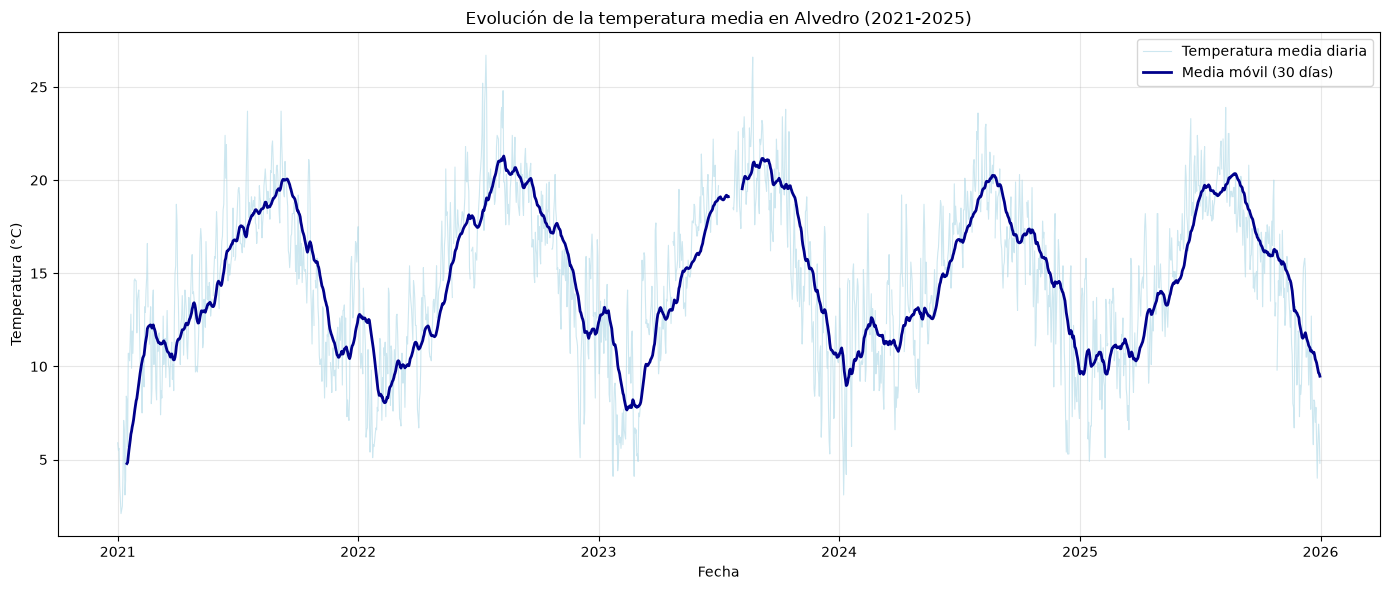

In [34]:
import matplotlib.pyplot as plt

# Calcular la media móvil de los últimos 30 días
df_clean["Media_movil_30d"] = (
    df_clean["Temp. media (ºC)"]
    .rolling(window=30, min_periods=15)
    .mean()
)

# Crear la gráfica
plt.figure(figsize=(14, 6))

# Temperatura media diaria
plt.plot(
    df_clean["Data"],
    df_clean["Temp. media (ºC)"],
    label="Temperatura media diaria",
    color="lightblue",
    alpha=0.6,
    linewidth=0.8
)

# Media móvil de 30 días
plt.plot(
    df_clean["Data"],
    df_clean["Media_movil_30d"],
    label="Media móvil (30 días)",
    color="darkblue",
    linewidth=2
)

plt.title("Evolución de la temperatura media en Alvedro (2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación:**

La gráfica muestra un patrón estacional de las temperaturas en Alvedro durante el período 2021-2025, con valores más elevados en verano y más bajos en invierno.

La media móvil de 30 días permite suavizar las variaciones diarias y visualizar mejor la evolución general de la temperatura.

A diferencia de la gráfica realizada antes de la limpieza, ya no aparecen los valores extremos erróneos de -9999 °C.

Las mediciones ausentes pueden producir interrupciones o afectar al cálculo de la media móvil.

### Gráfica 2. Evolución de la precipitación mensual

Se representa la precipitación total acumulada en cada mes durante el período 2021-2025.

El objetivo es identificar los meses más lluviosos y los períodos de menor precipitación, observando la variabilidad de las lluvias entre los diferentes años.

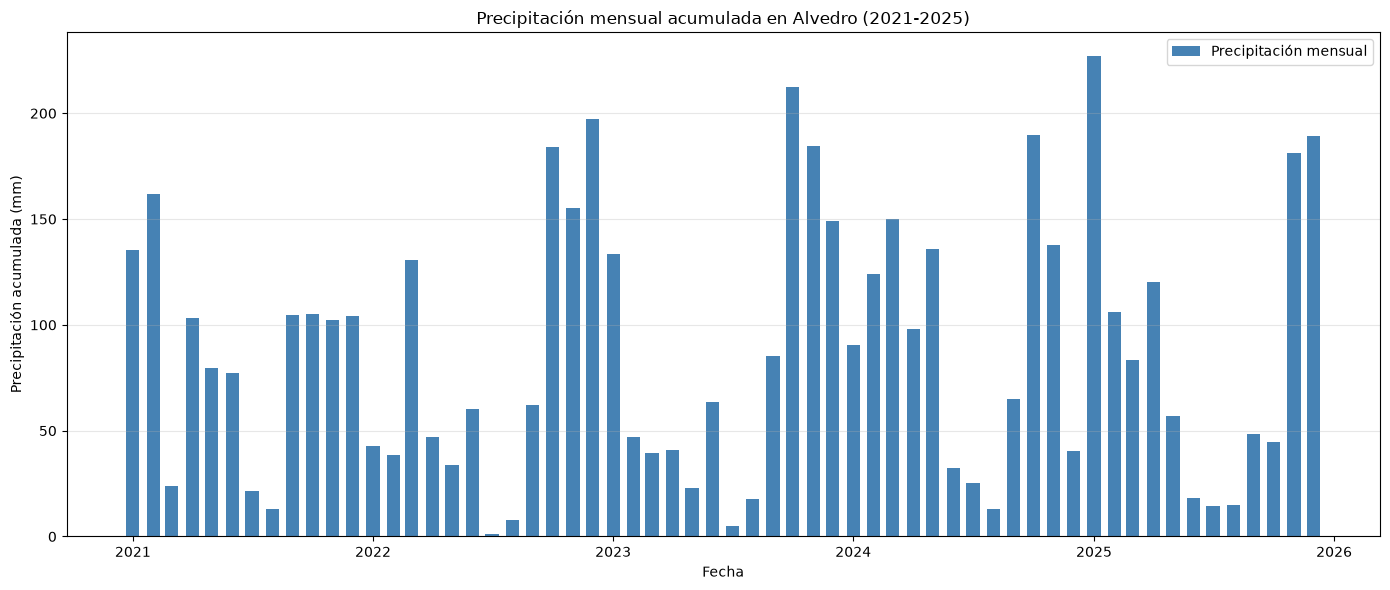

In [35]:
# Agrupar las precipitaciones por año y mes
precipitacion_mensual = (
    df_clean.set_index("Data")["Precipitación (mm)"]
    .resample("MS")
    .sum(min_count=1)
)

# Crear la gráfica
plt.figure(figsize=(14, 6))

plt.bar(
    precipitacion_mensual.index,
    precipitacion_mensual.values,
    width=20,
    color="steelblue",
    label="Precipitación mensual"
)

plt.title("Precipitación mensual acumulada en Alvedro (2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Precipitación acumulada (mm)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación:**

La gráfica muestra una elevada variabilidad de las precipitaciones mensuales en Alvedro durante el período 2021-2025.

En general, se observan mayores acumulaciones de lluvia durante el otoño y el invierno, mientras que los meses de verano presentan precipitaciones más reducidas.

Algunos meses superan los 200 mm de precipitación acumulada, mientras que otros registran cantidades muy bajas.

Los resultados deben interpretarse teniendo en cuenta la existencia de días sin mediciones, especialmente los 21 días ausentes de julio de 2023, que pueden provocar una subestimación del acumulado mensual.

### Gráfica 3. Comparación de las temperaturas de 2025 con la media del período

Se comparan las temperaturas medias mensuales del año 2025 con las temperaturas medias de cada mes durante el período 2021-2025.

Esta visualización permite identificar los meses en los que 2025 presentó temperaturas superiores o inferiores al promedio del conjunto de datos.

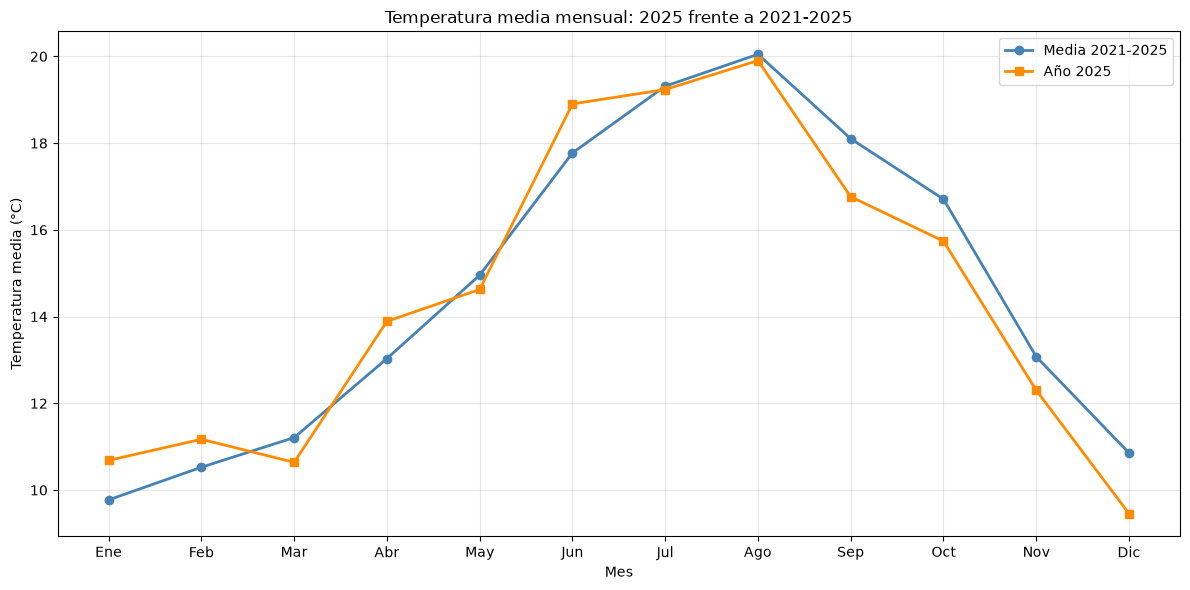

In [36]:
# Calcular la temperatura media de cada mes del período 2021-2025
media_historica = (
    df_clean.groupby("Mes")["Temp. media (ºC)"]
    .mean()
)

# Calcular la temperatura media mensual de 2025
media_2025 = (
    df_clean[df_clean["Año"] == 2025]
    .groupby("Mes")["Temp. media (ºC)"]
    .mean()
)

# Nombres de los meses
meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

# Crear la gráfica
plt.figure(figsize=(12, 6))

plt.plot(
    meses,
    media_historica.reindex(range(1, 13)),
    marker="o",
    linewidth=2,
    label="Media 2021-2025",
    color="steelblue"
)

plt.plot(
    meses,
    media_2025.reindex(range(1, 13)),
    marker="s",
    linewidth=2,
    label="Año 2025",
    color="darkorange"
)

plt.title("Temperatura media mensual: 2025 frente a 2021-2025")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación:**

La comparación muestra que las temperaturas medias mensuales de 2025 siguen un patrón estacional similar al promedio del período 2021-2025.

Durante enero, febrero, abril y junio se registraron temperaturas superiores al promedio, mientras que marzo, mayo y los meses de septiembre a diciembre presentaron valores inferiores.

Las temperaturas de julio y agosto fueron muy similares a la media del período.

En general, no se aprecian diferencias extremas entre ambas series, aunque destacan los valores ligeramente inferiores de 2025 durante los últimos meses del año.

La media de referencia incluye el propio año 2025 y se ha calculado a partir de las mediciones disponibles.

## 4.6. Medición de eficiencia

Se compara el tiempo de ejecución de dos métodos para calcular la amplitud térmica diaria (temperatura máxima menos temperatura mínima):

- Un bucle `for` que recorre los registros.
- Una operación vectorizada utilizando pandas.

Se emplea `%timeit` para medir el rendimiento y posteriormente se repite la comparación con un DataFrame cinco veces mayor.

In [ ]:
# Método 1: bucle for
amplitud_bucle = []

for tmax, tmin in zip(
    df_clean["Temp. máxima (ºC)"],
    df_clean["Temp. mínima (ºC)"]
):
    amplitud_bucle.append(tmax - tmin)


# Método 2: operación vectorizada con pandas
amplitud_vectorizada = (
    df_clean["Temp. máxima (ºC)"] -
    df_clean["Temp. mínima (ºC)"]
)

# Comprobamos que ambos métodos dan el mismo resultado
import numpy as np

print("¿Coinciden los resultados?",
      np.allclose(amplitud_bucle, amplitud_vectorizada, equal_nan=True))

print("\nPrimeros 10 valores calculados:")
display(amplitud_vectorizada.head(10))

¿Coinciden los resultados? True

Primeros 10 valores calculados:


0     5.8
1     6.6
2     5.4
3     7.1
4    10.9
5    11.1
6    11.1
7    12.0
8     7.3
9     3.6
dtype: float64

### Comparación de tiempos de ejecución

Una vez comprobado que ambos métodos producen los mismos resultados, se utiliza `%timeit` para medir su rendimiento.

Se comparan los tiempos de ejecución del bucle `for` y de la operación vectorizada de pandas utilizando el mismo conjunto de datos.

In [38]:
# Método 1: cálculo mediante bucle for
def calcular_amplitud_bucle(datos):
    resultado = []

    for tmax, tmin in zip(
        datos["Temp. máxima (ºC)"],
        datos["Temp. mínima (ºC)"]
    ):
        resultado.append(tmax - tmin)

    return resultado


# Método 2: cálculo vectorizado
def calcular_amplitud_vectorizada(datos):
    return (
        datos["Temp. máxima (ºC)"] -
        datos["Temp. mínima (ºC)"]
    )

In [39]:
print("Tiempo del bucle for:")
%timeit calcular_amplitud_bucle(df_clean)

print("\nTiempo de la operación vectorizada:")
%timeit calcular_amplitud_vectorizada(df_clean)

Tiempo del bucle for:
237 μs ± 3.72 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)

Tiempo de la operación vectorizada:
66.4 μs ± 1.66 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


**Resultados:**

Con el DataFrame original de 1826 registros, el bucle `for` tarda aproximadamente 237 µs, mientras que la operación vectorizada tarda 66,4 µs.

Por tanto, la operación vectorizada es aproximadamente 3,57 veces más rápida, gracias a que pandas permite realizar cálculos sobre columnas completas mediante operaciones optimizadas.

### Comparación con un DataFrame cinco veces mayor

Se repiten las mediciones de rendimiento utilizando un DataFrame cinco veces más grande, generado mediante `pd.concat()`.

El objetivo es comprobar cómo afecta el aumento del número de registros al tiempo de ejecución de ambos métodos.

In [40]:
# Crear un DataFrame cinco veces mayor
df_grande = pd.concat(
    [df_clean] * 5,
    ignore_index=True
)

# Comprobar el número de registros
print("Registros originales:", len(df_clean))
print("Registros ampliados:", len(df_grande))

# Comprobar que ambos métodos siguen dando el mismo resultado
resultado_bucle = calcular_amplitud_bucle(df_grande)
resultado_vectorizado = calcular_amplitud_vectorizada(df_grande)

print(
    "¿Coinciden los resultados?",
    np.allclose(resultado_bucle, resultado_vectorizado, equal_nan=True)
)

Registros originales: 1826
Registros ampliados: 9130
¿Coinciden los resultados? True


In [41]:
print("Bucle for (DataFrame grande):")
%timeit calcular_amplitud_bucle(df_grande)

print("\nOperación vectorizada (DataFrame grande):")
%timeit calcular_amplitud_vectorizada(df_grande)

Bucle for (DataFrame grande):
1.12 ms ± 10.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)

Operación vectorizada (DataFrame grande):
70.3 μs ± 821 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


### Conclusión de la comparación de eficiencia

Con 1826 registros, la operación vectorizada es aproximadamente **3,57 veces más rápida** que el bucle `for`, mientras que con 9130 registros la diferencia aumenta hasta **15,93 veces**.

Al multiplicar por cinco el número de registros, el tiempo del bucle aumenta considerablemente, mientras que el de la operación vectorizada apenas varía en esta prueba.

Esto se debe a que las operaciones vectorizadas aprovechan las implementaciones optimizadas de pandas y NumPy, evitando gran parte de la sobrecarga de ejecutar las operaciones individualmente desde Python.

## 4.7. Carga de datos en PostgreSQL

Se utiliza PostgreSQL ejecutado mediante Docker Compose para almacenar los datos meteorológicos limpios.

La conexión se realiza mediante SQLAlchemy, utilizando las variables de configuración almacenadas en el archivo `.env`.

Posteriormente, se cargará el DataFrame mediante `to_sql()` y se realizarán consultas SQL para comparar los resultados con pandas.

### Conexión con la base de datos

In [42]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Localizar el archivo .env en la raíz del proyecto
ruta_env = Path("../.env").resolve()

# Cargar las variables del archivo .env
load_dotenv(ruta_env)

# Crear la URL de conexión a PostgreSQL
url_conexion = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("POSTGRES_USER"),
    password=os.getenv("POSTGRES_PASSWORD"),
    host="localhost",
    port=int(os.getenv("POSTGRES_PORT")),
    database=os.getenv("POSTGRES_DB")
)

# Crear el motor de conexión
engine = create_engine(url_conexion)

# Comprobar que PostgreSQL responde
with engine.connect() as conexion:
    resultado = conexion.execute(text("SELECT version();"))
    print("Conexión establecida correctamente.")
    print(resultado.scalar())

Conexión establecida correctamente.
PostgreSQL 17.11 on x86_64-pc-linux-musl, compiled by gcc (Alpine 15.2.0) 15.2.0, 64-bit


### Carga del DataFrame en PostgreSQL

Se utiliza el método `to_sql()` de pandas para cargar el conjunto de datos meteorológicos limpio en PostgreSQL.

Se crea una tabla llamada `meteo_alvedro` con los registros correspondientes al período 2021-2025.

La carga se realiza de forma que pueda repetirse al ejecutar nuevamente el notebook.

In [43]:
# Cargar los datos limpios en PostgreSQL
df_clean.to_sql(
    name="meteo_alvedro",
    con=engine,
    if_exists="replace",
    index=False
)

print("Datos cargados correctamente en PostgreSQL.")

Datos cargados correctamente en PostgreSQL.


In [44]:
# Consultar el número de registros almacenados
consulta = text("SELECT COUNT(*) FROM meteo_alvedro;")

with engine.connect() as conexion:
    total = conexion.execute(consulta).scalar()

print("Registros almacenados en PostgreSQL:", total)
print("Registros del DataFrame:", len(df_clean))
print("¿Coinciden?", total == len(df_clean))

Registros almacenados en PostgreSQL: 1826
Registros del DataFrame: 1826
¿Coinciden? True


### Consulta SQL 1. Temperatura media anual

Se calcula la temperatura media de cada año mediante una consulta SQL sobre la tabla `meteo_alvedro`.

Los resultados se comparan con los obtenidos anteriormente utilizando pandas para verificar que ambos métodos producen los mismos valores.

In [45]:
# Consulta SQL para calcular la temperatura media anual
consulta_sql_1 = """
SELECT
    EXTRACT(YEAR FROM "Data")::INTEGER AS anio,
    ROUND(AVG("Temp. media (ºC)")::NUMERIC, 2) AS temperatura_media
FROM meteo_alvedro
GROUP BY EXTRACT(YEAR FROM "Data")
ORDER BY anio;
"""

# Ejecutar la consulta y mostrar los resultados
resultado_sql_1 = pd.read_sql(
    text(consulta_sql_1),
    con=engine
)

display(resultado_sql_1)

,anio,temperatura_media
0,2021,14.12
1,2022,14.98
2,2023,14.91
3,2024,14.45
4,2025,14.45


In [46]:
# Comparar los resultados de SQL con pandas
comparacion = resultado_sql_1.copy()

comparacion["media_pandas"] = (
    comparacion["anio"]
    .map(temperaturas_anuales)
    .astype(float)
)

comparacion["temperatura_media"] = (
    comparacion["temperatura_media"].astype(float)
)

comparacion["coinciden"] = np.isclose(
    comparacion["temperatura_media"],
    comparacion["media_pandas"]
)

display(comparacion)

print("¿Coinciden todos los resultados?",
      comparacion["coinciden"].all())

,anio,temperatura_media,media_pandas,coinciden
0,2021,14.12,14.12,True
1,2022,14.98,14.98,True
2,2023,14.91,14.91,True
3,2024,14.45,14.45,True
4,2025,14.45,14.45,True


¿Coinciden todos los resultados? True


**Resultados:**

La consulta SQL devuelve las mismas temperaturas medias anuales que las calculadas anteriormente con pandas.

Se ha verificado la coincidencia de los resultados para los cinco años del período 2021-2025 mediante `np.isclose()`.

Por tanto, se confirma que la consulta SQL reproduce correctamente el cálculo realizado con pandas.

### Consulta SQL 2. Mes más lluvioso y más seco

Se calcula la precipitación acumulada de cada mes y año mediante SQL y posteriormente se obtiene la media de cada mes del calendario durante el período 2021-2025.

Los resultados se comparan con los obtenidos anteriormente mediante pandas para comprobar su coincidencia.

In [47]:
consulta_sql_2 = """
WITH lluvia_por_mes AS (
    SELECT
        EXTRACT(YEAR FROM "Data")::INTEGER AS anio,
        EXTRACT(MONTH FROM "Data")::INTEGER AS mes,
        SUM("Precipitación (mm)") AS total_lluvia
    FROM meteo_alvedro
    GROUP BY anio, mes
)
SELECT
    mes,
    ROUND(AVG(total_lluvia)::NUMERIC, 2) AS precipitacion_media
FROM lluvia_por_mes
GROUP BY mes
ORDER BY mes;
"""

resultado_sql_2 = pd.read_sql(
    text(consulta_sql_2),
    con=engine
)

display(resultado_sql_2)

,mes,precipitacion_media
0,1,125.84
1,2,95.46
2,3,85.38
3,4,81.88
4,5,65.88
5,6,50.44
6,7,13.44
7,8,13.42
8,9,73.00
9,10,147.14


In [48]:
# Crear la tabla de comparación
comparacion_lluvia = resultado_sql_2.copy()

# Incorporar los resultados obtenidos con pandas
comparacion_lluvia["media_pandas"] = (
    comparacion_lluvia["mes"]
    .map(media_lluvia_mensual)
    .astype(float)
)

# Convertir los resultados SQL a float
comparacion_lluvia["precipitacion_media"] = (
    comparacion_lluvia["precipitacion_media"].astype(float)
)

# Comparar los valores
comparacion_lluvia["coinciden"] = np.isclose(
    comparacion_lluvia["precipitacion_media"],
    comparacion_lluvia["media_pandas"]
)

display(comparacion_lluvia)

print(
    "¿Coinciden todos los resultados?",
    comparacion_lluvia["coinciden"].all()
)

,mes,precipitacion_media,media_pandas,coinciden
0,1,125.84,125.84,True
1,2,95.46,95.46,True
2,3,85.38,85.38,True
3,4,81.88,81.88,True
4,5,65.88,65.88,True
5,6,50.44,50.44,True
6,7,13.44,13.44,True
7,8,13.42,13.42,True
8,9,73.00,73.00,True
9,10,147.14,147.14,True


¿Coinciden todos los resultados? True


**Resultados:**

La consulta SQL reproduce correctamente los resultados de precipitación media mensual obtenidos con pandas.

Se confirma que noviembre es el mes más lluvioso, con una media de 152,12 mm, mientras que agosto es el más seco, con 13,42 mm.

Los resultados coinciden en los 12 meses analizados, verificándose mediante `np.isclose()`.

Los acumulados pueden estar subestimados en los meses con mediciones ausentes.

### Consulta SQL 3. Número de días con temperaturas máximas de al menos 30 °C

Se plantea una pregunta adicional: ¿cuántos días registraron temperaturas máximas iguales o superiores a 30 °C en cada año?

Se realiza el recuento mediante SQL y se compara con el resultado obtenido con pandas.

Los días sin mediciones válidas de temperatura máxima no se consideran días calurosos confirmados.

In [49]:
consulta_sql_3 = """
SELECT
    EXTRACT(YEAR FROM "Data")::INTEGER AS anio,
    COUNT(*) FILTER (
        WHERE "Temp. máxima (ºC)" >= 30
    ) AS dias_calor
FROM meteo_alvedro
GROUP BY anio
ORDER BY anio;
"""

resultado_sql_3 = pd.read_sql(
    text(consulta_sql_3),
    con=engine
)

display(resultado_sql_3)

,anio,dias_calor
0,2021,5
1,2022,8
2,2023,11
3,2024,3
4,2025,6


In [50]:
# Calcular los días con temperaturas >= 30 °C utilizando pandas
dias_calor_pandas = (
    df_clean["Temp. máxima (ºC)"].ge(30)
    .groupby(df_clean["Año"])
    .sum()
)

# Comparar con los resultados de PostgreSQL
comparacion_calor = resultado_sql_3.copy()

comparacion_calor["dias_pandas"] = (
    comparacion_calor["anio"]
    .map(dias_calor_pandas)
)

comparacion_calor["coinciden"] = (
    comparacion_calor["dias_calor"] ==
    comparacion_calor["dias_pandas"]
)

display(comparacion_calor)

print(
    "¿Coinciden todos los resultados?",
    comparacion_calor["coinciden"].all()
)

,anio,dias_calor,dias_pandas,coinciden
0,2021,5,5,True
1,2022,8,8,True
2,2023,11,11,True
3,2024,3,3,True
4,2025,6,6,True


¿Coinciden todos los resultados? True


**Resultados:**

El año con mayor número de días con temperaturas máximas iguales o superiores a 30 °C fue 2023, con 11 días, seguido de 2022 con 8 días.

Por el contrario, 2024 registró el menor número, con únicamente 3 días.

Los resultados obtenidos mediante SQL coinciden exactamente con los calculados mediante pandas para los cinco años.

Debe tenerse en cuenta que existen días sin mediciones válidas, especialmente durante julio de 2023, por lo que los recuentos representan los días calurosos confirmados.


**Conclusión del apartado 4.7:**

Se ha configurado PostgreSQL mediante Docker Compose, utilizando variables de entorno para la configuración.

Los 1826 registros del conjunto de datos limpio se han cargado correctamente mediante `to_sql()`.

Se han realizado tres consultas SQL:
1. Temperatura media anual.
2. Precipitación acumulada media por mes.
3. Número de días con temperaturas máximas de al menos 30 °C.

Los resultados de las tres consultas se han contrastado con pandas, obteniendo coincidencia en todos los casos.